# goldbot framework backtest: ORB with funded-account rules

This notebook runs the **real engine** (`goldbot/`: strategy plug-in, funded risk manager, OCO
orders, time exits) bar by bar on 4.9 years of XAUUSD M1 data, through the simulated broker.
Nothing here is a separate research model: it is the code that trades.

Account: 6,000 USD funded account. Rules: daily loss limit 200, first-week loss limit 400,
stop trading after +600 in a week, max 2 trades a day, 90 USD risk per trade, 15 USD buffer.
Costs: spread 0.30, slippage 0.10 on entries and stops.

Strategy settings were chosen in the research phase on 2022-2024 only (best consistent ORB
variant: COMEX open 08:20 New York, 60 minute range, stop at range midpoint, 3R target, daily
trend filter, cancel if the other side breaks first). **2025-2026 is the holdout.** The research
already showed this variant is not statistically significant (t about 0.6 in both periods);
this notebook checks what the account would have experienced.

The LLM committee is not backtested over years (thousands of paid calls, and an LLM's answers
cannot be replayed exactly). Section 7 checks its plumbing with the offline fake provider;
`backtest/llm_replay.py` evaluates a real provider on a sample when you supply a key.

In [1]:
import sys, os, copy, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, ".."); sys.path.insert(0, ".")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import engine as E, orb as O
from goldbot.config import Config, RiskConfig, JudgeConfig
from goldbot.backtest import run_backtest
from goldbot.judge import Committee
from goldbot.judge.providers import make_provider

C1, C2, C3, C4 = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6"
GRID, INK, MUTED = "#e3e2de", "#0b0b0b", "#52514e"
plt.rcParams.update({"figure.figsize": (11, 4.2), "figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
                     "grid.linewidth": 0.8, "axes.edgecolor": MUTED, "xtick.color": MUTED,
                     "ytick.color": MUTED, "lines.linewidth": 2, "axes.titleweight": "bold",
                     "axes.titlesize": 12, "legend.frameon": False})
HOLDOUT = pd.Timestamp("2025-01-01")
m1 = E.load_m1()
ORB = dict(range_min=60, window_min=120, stop="mid", target_r=3.0, trend_filter=True)
def cfg_for(sessions, **risk):
    return Config(strategy_params=dict(sessions=sessions, **ORB),
                  risk=RiskConfig(**{"risk_per_trade_usd": 90, "loss_buffer_usd": 15, "volume_max": 5.0, **risk}))
print(f"M1 bars {len(m1):,}: {m1.time.min():%Y-%m-%d} to {m1.time.max():%Y-%m-%d}")

M1 bars 1,682,112: 2022-01-02 to 2026-11-13


## 1. Parity: engine vs research engine (rules relaxed so every signal trades)

In [2]:
free = dict(daily_loss_limit=1e9, first_week_loss_limit=1e9, weekly_profit_target=1e9)
eng = run_backtest(cfg_for(("ny_comex",), **free), m1)["trades"]
ref = O.run_orb(O.M1(m1), O.OrbParams(session="ny_comex", **{k: ORB[k] for k in ("range_min", "window_min", "stop", "target_r", "trend_filter")}))
a = eng.assign(d=eng.entry_time.dt.date).set_index("d"); b = ref.assign(d=pd.to_datetime(ref.entry_time).dt.date).set_index("d")
j = a.join(b, how="outer", rsuffix="_ref")
print(f"trades: engine {len(a)}, research {len(b)}; days only in one of them: {j.entry.isna().sum() + j.entry_ref.isna().sum()}")
both = j.dropna(subset=["entry", "entry_ref"])
print(f"same direction on every common day: {(np.where(both.side == 'BUY', 1, -1) == both.dir).all()}")
print(f"entry price max difference: {(both.entry - both.entry_ref).abs().max():.4f}")
print(f"R correlation: {both.R.corr(both.R_ref):.4f} (small differences: target fixed at order time, lot rounding)")
print(f"avg R engine {a.R.mean():+.3f} vs research {b.R.mean():+.3f}")

trades: engine 568, research 568; days only in one of them: 0
same direction on every common day: True
entry price max difference: 0.0000
R correlation: 0.9896 (small differences: target fixed at order time, lot rounding)
avg R engine +0.056 vs research +0.054


## 2. Funded account replay: New York only (1 trade a day) and London + New York (up to 2)

In [3]:
runs = {}
for name, sess in [("NY only", ("ny_comex",)), ("London + NY", ("london", "ny_comex"))]:
    res = run_backtest(cfg_for(sess), m1, start_equity=6000)
    runs[name] = res
def stats(tr):
    if len(tr) == 0: return {}
    w = tr.groupby("week").pnl.sum()
    eq = tr.pnl.cumsum(); dd = (eq - eq.cummax()).min()
    return {"trades": len(tr), "win %": 100 * (tr.pnl > 0).mean(), "avg R": tr.R.mean(),
            "t-stat": tr.R.mean() / tr.R.std() * np.sqrt(len(tr)), "total USD": tr.pnl.sum(),
            "max DD USD": dd, "weeks": len(w), "weeks >= +600": int((w >= 600).sum()),
            "weeks <= -400": int((w <= -400).sum()), "worst day USD": tr.groupby("day").pnl.sum().min()}
rows = []
for name, res in runs.items():
    tr = res["trades"]
    for per, msk in [("2022-2024 (in-sample)", tr.entry_time < HOLDOUT), ("2025-2026 (holdout)", tr.entry_time >= HOLDOUT), ("all", tr.entry_time.notna())]:
        rows.append({"variant": name, "period": per, **stats(tr[msk])})
pd.DataFrame(rows).set_index(["variant", "period"]).round(2)

trades  win %  avg R  t-stat  total USD  \
variant     period                                                           
NY only     2022-2024 (in-sample)     305  42.62   0.06    0.72    1555.63   
            2025-2026 (holdout)       263  37.26   0.05    0.61    1239.47   
            all                       568  40.14   0.06    0.94    2795.10   
London + NY 2022-2024 (in-sample)     600  37.00  -0.07   -1.20   -3665.64   
            2025-2026 (holdout)       507  35.31  -0.03   -0.49   -1366.19   
            all                      1107  36.22  -0.05   -1.22   -5031.83   

                                   max DD USD  weeks  weeks >= +600  \
variant     period                                                    
NY only     2022-2024 (in-sample)    -2174.23    130              0   
            2025-2026 (holdout)      -1849.40     92              1   
            all                      -3147.38    222              1   
London + NY 2022-2024 (in-sample)    -5137.48    155              3   
            2025-2026 (holdout)      -5131.14     98              4   
            all                      -9030.67    252              7   

                                   weeks <= -400  worst day USD  
variant     period                                               
NY only     2022-2024 (in-sample)              0        -111.55  
            2025-2026 (holdout)                0        -100.14  
            all                                0        -111.55  
London + NY 2022-2024 (in-sample)              6        -191.21  
            2025-2026 (holdout)               12        -191.45  
            all                               18        -191.45

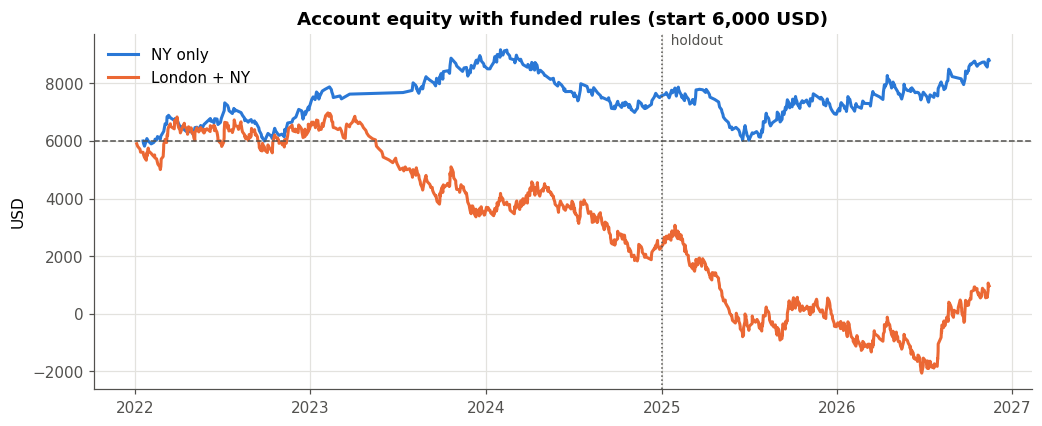

In [4]:
fig, ax = plt.subplots()
for (name, res), col in zip(runs.items(), [C1, C2]):
    tr = res["trades"]; ax.plot(tr.exit_time, 6000 + tr.pnl.cumsum(), color=col, label=name)
ax.axhline(6000, color=MUTED, lw=1, ls="--"); ax.axvline(HOLDOUT, color=MUTED, lw=1, ls=":")
ax.text(HOLDOUT, ax.get_ylim()[1], "  holdout", va="top", color=MUTED, fontsize=9)
ax.set_title("Account equity with funded rules (start 6,000 USD)"); ax.set_ylabel("USD"); ax.legend(); plt.show()

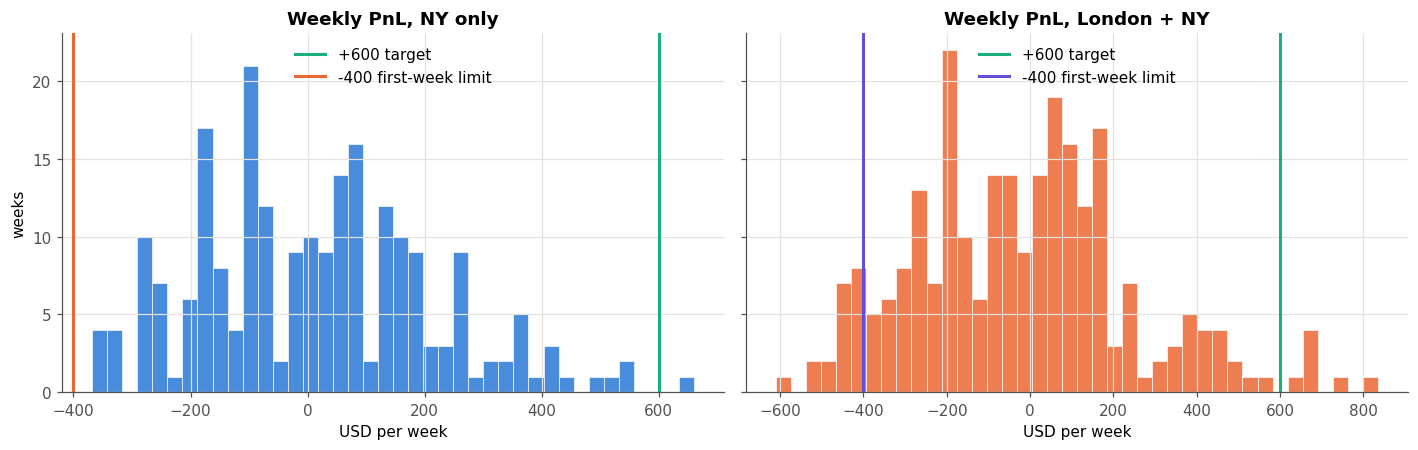

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, (name, res), col in zip(axs, runs.items(), [C1, C2]):
    w = res["trades"].groupby("week").pnl.sum()
    ax.hist(w, bins=40, color=col, alpha=0.85, edgecolor="white", linewidth=0.5)
    ax.axvline(600, color=C3, lw=2, label="+600 target"); ax.axvline(-400, color=C2 if col != C2 else C4, lw=2, label="-400 first-week limit")
    ax.set_title(f"Weekly PnL, {name}"); ax.set_xlabel("USD per week"); ax.legend()
axs[0].set_ylabel("weeks"); fig.tight_layout(); plt.show()

## 3. How often the rules actually stepped in

In [6]:
for name, res in runs.items():
    d = res["decisions"]
    if d.empty: print(name, "no rejections"); continue
    rej = d[~d.approved]
    kinds = rej.reason.str.extract(r"^(daily limit|first-week limit|weekly target|stop too wide|\d trades)")[0].fillna("other")
    print(f"{name}: setups rejected by the risk manager: {len(rej)}  ->  {kinds.value_counts().to_dict()}")

NY only no rejections
London + NY: setups rejected by the risk manager: 98  ->  {'daily limit': 83, 'weekly target': 15}


## 4. The funded-account question: first week from a fresh start

For every week in the data, start a fresh account that Monday and follow the engine's trades:
does it make **+600** before losing **400**, within that first week? (Daily 200 and weekly target
rules are applied by the engine; the 400 first-week stop is applied on the trade path here.)

In [7]:
def first_week_outcomes(tr, target=600, limit=400):
    out = []
    for w, g in tr.groupby("week"):
        eq = g.sort_values("exit_time").pnl.cumsum().to_numpy()
        hit = np.flatnonzero(eq >= target); bust = np.flatnonzero(eq <= -limit)
        h, b = (hit[0] if len(hit) else 10**9), (bust[0] if len(bust) else 10**9)
        out.append("pass (+600)" if h < b else ("fail (-400)" if b < h else "neither"))
    return pd.Series(out).value_counts(normalize=True).mul(100).round(1)
pd.DataFrame({name: first_week_outcomes(res["trades"]) for name, res in runs.items()}).fillna(0)

,NY only,London + NY
fail (-400),0.0,7.9
neither,99.5,89.3
pass (+600),0.5,2.8


NY only: first week P(pass +600) = 0.5%, P(fail -400) = 0.1%, neither = 99.4%


London + NY: first week P(pass +600) = 2.5%, P(fail -400) = 4.8%, neither = 92.8%


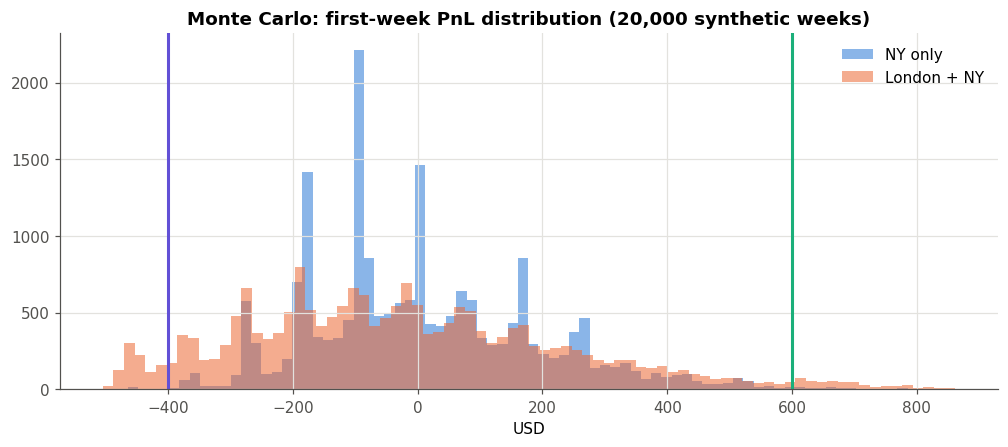

In [8]:
# Monte Carlo: build 20,000 synthetic weeks from resampled trading days (keeps each day's
# trades together, so the daily limit structure is preserved)
rng = np.random.default_rng(7)
def mc_weeks(tr, n=20000, target=600, limit=400):
    days = [g.sort_values("exit_time").pnl.to_numpy() for _, g in tr.groupby("day")]
    n_days = tr.groupby("week").day.nunique().median()
    allw = pd.date_range(tr.entry_time.min(), tr.entry_time.max(), freq="W").size
    # include days with no trade: the share of trading days that had a trade
    p_trade = len(days) / max(1, allw * 5)
    res = {"pass": 0, "fail": 0, "neither": 0}; finals = []
    for _ in range(n):
        eq, done = 0.0, None
        for _d in range(5):
            if rng.random() > p_trade: continue
            for x in days[rng.integers(len(days))]:
                eq += x
                if eq >= target: done = "pass"; break
                if eq <= -limit: done = "fail"; break
            if done: break
        res[done or "neither"] += 1; finals.append(eq)
    return {k: 100 * v / n for k, v in res.items()}, np.array(finals)
mc = {}
for name, res in runs.items():
    p, finals = mc_weeks(res["trades"]); mc[name] = finals
    print(f"{name}: first week P(pass +600) = {p['pass']:.1f}%, P(fail -400) = {p['fail']:.1f}%, neither = {p['neither']:.1f}%")
fig, ax = plt.subplots()
for (name, f), col in zip(mc.items(), [C1, C2]):
    ax.hist(f, bins=80, color=col, alpha=0.55, label=name)
ax.axvline(600, color=C3, lw=2); ax.axvline(-400, color=C4, lw=2)
ax.set_title("Monte Carlo: first-week PnL distribution (20,000 synthetic weeks)"); ax.set_xlabel("USD"); ax.legend(); plt.show()

## 5. Cost stress (NY only)

In [9]:
rows = []
for sp, sl in [(0.15, 0.05), (0.30, 0.10), (0.50, 0.10), (0.30, 0.30), (0.50, 0.30)]:
    tr = run_backtest(cfg_for(("ny_comex",)), m1, spread=sp, slip=sl)["trades"]
    rows.append({"spread": sp, "slippage": sl, **stats(tr)})
pd.DataFrame(rows).set_index(["spread", "slippage"])[["trades", "avg R", "t-stat", "total USD", "max DD USD", "weeks >= +600", "weeks <= -400"]].round(2)

,,trades,avg R,t-stat,total USD,max DD USD,weeks >= +600,weeks <= -400
spread,slippage,,,,,,,
0.15,0.05,567,0.09,1.52,4452.42,-2466.24,1,1
0.30,0.10,568,0.06,0.94,2795.10,-3147.38,1,0
0.50,0.10,565,0.01,0.16,421.29,-3589.09,1,0
0.30,0.30,568,-0.01,-0.08,-258.10,-4210.95,1,1
0.50,0.30,565,-0.05,-0.85,-2564.51,-5068.48,1,0


## 6. Year by year (NY only)

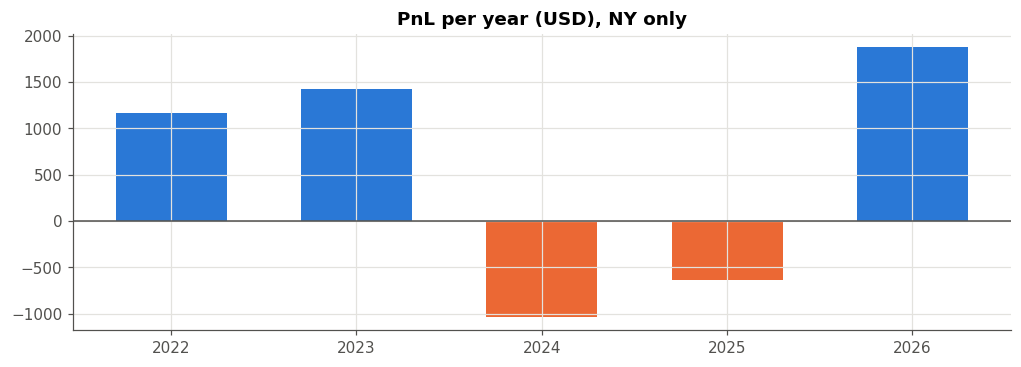

,trades,win_pct,avg_R,pnl_usd
entry_time,,,,
2022,106,43.40,0.12,1166.50
2023,72,44.44,0.22,1424.03
2024,127,40.94,-0.09,-1034.89
2025,145,35.86,-0.05,-634.02
2026,118,38.98,0.18,1873.49


In [10]:
tr = runs["NY only"]["trades"]
y = tr.groupby(tr.entry_time.dt.year).agg(trades=("pnl", "size"), win_pct=("pnl", lambda x: 100 * (x > 0).mean()),
                                          avg_R=("R", "mean"), pnl_usd=("pnl", "sum"))
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.bar(y.index.astype(str), y.pnl_usd, color=[C1 if v >= 0 else C2 for v in y.pnl_usd], width=0.6)
ax.axhline(0, color=MUTED, lw=1); ax.set_title("PnL per year (USD), NY only"); plt.show()
y.round(2)

## 7. Committee plumbing (offline fake provider)

The fake provider approves only when the daily trend agrees with the trade. Because the strategy
already filters on the daily trend, it should approve almost everything; the point is to show
the committee can only remove trades, never add or change them, and that the engine records
every decision.

In [11]:
cfg = cfg_for(("ny_comex",)); cfg.judge = JudgeConfig(enabled=True, provider="fake", use_chair=True)
res_c = run_backtest(cfg, m1, start="2025-01-01", committee=Committee(cfg.judge, provider=make_provider("fake")))
base = run_backtest(cfg_for(("ny_comex",)), m1, start="2025-01-01")["trades"]
d = res_c["decisions"]; cm = d[d.stage == "committee"]
print(f"committee decisions: {len(cm)}, approved {cm.approved.sum()}, rejected {(~cm.approved).sum()}")
print(f"trades with committee: {len(res_c['trades'])} vs without: {len(base)}; subset: {set(res_c['trades'].group) <= set(base.group)}")

committee decisions: 483, approved 483, rejected 0
trades with committee: 263 vs without: 263; subset: True


## 8. Conclusions

**The framework works; the strategy does not meet the account's goal.**

| Check | Result |
|---|---|
| Engine vs research engine | 568 vs 568 trades, same days, same sides, same entries, R correlation 0.99 |
| NY only, 2022-2024 / 2025-2026 | +0.06 R per trade in both periods, t about 0.7 and 0.6: consistent but not significant |
| NY only, whole period | +2.8k USD on 6k over 4.9 years, max drawdown about -3.1k, worst day about -112 |
| Weekly +600 target | reached in 1 of 222 weeks; first-week pass about 0.5% (history and Monte Carlo agree) |
| London + NY (2 trades a day) | loses about -5k, 18 weeks at or below -400: the London leg destroys value |
| Costs | the edge disappears with a 0.50 spread or 0.30 slippage |
| Daily rule | never broken; worst day about -112 (NY only) and -191 (London + NY) |

What this means for the funded account:
1. With 90 USD risk and one trade a day, +600 in a week needs about 7R of net profit in five
   trades. The strategy averages +0.06R. The target is out of reach without risking much more,
   and more risk raises the chance of failing far faster than the chance of passing.
2. Many funded programs also have a maximum total drawdown. A -3.1k drawdown on 6k would break
   any usual limit, even though the daily rule held.
3. Use the framework in **alert mode on a demo account** as a forward test (journal every setup
   and compare with this backtest) before any real decision. Do not enable the London leg.
4. The LLM committee is veto-only and switchable. Whether it improves selection is an empirical
   question: run `backtest/llm_replay.py` on the holdout with your provider and key, and keep it
   only if approved setups do clearly better than rejected ones.